## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Loading model runs
2. Setting technology colors for some visualisations
3. All functions
5. Inspecting results and using of functions for visualisations

### 1) Imports

In [1]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2020, 2030, 2040, 2050]

### 2) Load networks

In [2]:
RESULTS_DIR = Path("results/temporal_scenarios")
SCENARIOS = ["default_tech_low_carbon", "default_tech_high_carbon", "improved_tech_low_carbon", "improved_tech_high_carbon"]
LABELS = {
    "default_tech_low_carbon": "Default technology | default CO₂ price",
    "default_tech_high_carbon": "Default technology | high CO₂ price",
    "improved_tech_low_carbon": "Improved technology | default CO₂ price",
    "improved_tech_high_carbon": "Improved technology | high CO₂ price",
}
COLORS = {
    "default_tech_low_carbon": "#2878B5",
    "default_tech_high_carbon": "#4C8AAE",
    "improved_tech_low_carbon": "#9E6A45",
    "improved_tech_high_carbon": "#D97732",
}

networks = {}
for scenario in SCENARIOS:
    file = RESULTS_DIR / f"{scenario}.nc"
    if not file.exists():
        raise FileNotFoundError(f"Missing scenario result: {file}")
    networks[scenario] = pypsa.Network(str(file))

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


### 3) Setting technology colors for visualization

In [3]:
tech_colors = {
    # Electricity generation
    "CCGT": "#E68127",                         # Orange
    "CCGT - existing": "#F5B97D",              # Light orange
    "CCGT CCS": "#A84B0F",                     # Burnt orange
    "Biomass plant": "#7CAD45",                # Leaf green
    "Biomass plant CCS": "#276339",            # Dark green
    "Nuclear plant": "#8C58B5",                # Purple
    "Solar": "#E9C52B",                        # Golden yellow
    "Wind onshore": "#37B9AA",                 # Turquoise
    "Wind offshore": "#087F86",                # Deep teal


    # Transport
    "BEV": "#4779D1",                          # Blue
    "BEV - existing": "#A5BEF0",               # Light blue
    "ICE car": "#BC6951",                      # Terracotta
    "ICE car - existing": "#E5AE9D",           # Light terracotta

    # Electricity storage
    "Battery": "#483A88",                      # Indigo

    # Residential demand and heating
    "Residential Appliance": "#737D8C",        # Slate grey
    "Residential gas boiler": "#D8A026",       # Ochre
    "Residential gas boiler - existing": "#EFD18B",
    "Residential heat pump": "#56B5E4",        # Sky blue

    # Large-scale heating
    "Large-scale heat pump": "#008EB8",        # Cyan blue
    "Large-scale heat pump - existing": "#8DD5E7",

    # Industrial boilers
    "Industrial gas boiler": "#A88B55",        # Sand brown
    "Industrial gas boiler - existing": "#D8C7A5",

    # Industrial machinery
    "Industrial machinery - fossil": "#996343",
    "Industrial machinery - fossil - existing": "#CDAF94",
    "Industrial machinery - fossil CCS": "#593B27",
    "Industrial machinery - electricity": "#234D96",

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#B44742",      # Brick red
    "Industrial HTP - fossil - existing": "#DD9692",
    "Industrial HTP - fossil CCS": "#702C36",  # Burgundy

    # Hydrogen production
    "SMR": "#CC743D",                         # Copper
    "SMR - existing": "#E8B79C",
    "SMR with CCS": "#80532B",                # Bronze
    "SMR with CCS - existing": "#BCA07D",
    "Electrolysis": "#7166CF",                # Blue-violet
    "Electrolysis - existing": "#B9B2EB",

    # Emissions
    "CO2 atmosphere": "#333333",              # Charcoal
}

# Alternative names used in your original dictionary.
tech_colors.update({
    "Solar PV": tech_colors["Solar"],
    "Wind turbine - onshore": tech_colors["Wind onshore"],
    "Wind turbine - offshore": tech_colors["Wind offshore"],
})

tech_colors.update({
    # Electricity generation
    "Biomass plant CCS": "#228833",       # Green
    "CCGT": "#F57900",                    # Orange
    "CCGT - existing": "#FFC180",         # Light orange
    "CCGT CCS": "#8C510A",                # Dark brown

    # Emissions
    "CO2 atmosphere": "#333333",          # Charcoal

    # Transport
    "ICE car": "#0077BB",                 # Blue
    "ICE car - existing": "#91C9EB",       # Light blue

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#CC3311",                 # Vermilion
    "Industrial HTP - fossil - existing": "#F3A18D",      # Light salmon
    "Industrial HTP - fossil CCS": "#882255",             # Burgundy

    # Industrial low-temperature heating
    "Industrial gas boiler": "#AA4499",                  # Purple
    "Industrial gas boiler - existing": "#D8ACD0",       # Light purple

    # Industrial machinery
    "Industrial machinery - fossil": "#008878",          # Teal
    "Industrial machinery - fossil - existing": "#8CD3C7",  # Light teal
    "Industrial machinery - fossil CCS": "#004C46",      # Dark teal

    # Residential heating
    "Residential gas boiler": "#D4AA00",                 # Mustard
    "Residential gas boiler - existing": "#F5DF87",       # Light yellow

    # Hydrogen production
    "SMR": "#6655CC",                     # Violet
    "SMR - existing": "#BDB3EA",          # Light violet
    "SMR with CCS": "#596B28",            # Olive
    "SMR with CCS - existing": "#BCC995", # Light olive
})

### 4) Functions

In [4]:
def sys_snapshots(n, year):
    if not isinstance(n.snapshots, pd.MultiIndex):
        raise ValueError('Expected multi-period snapshots.')
    return n.snapshots[n.snapshots.get_level_values(0) == year]


def sys_weights(n, snapshots):
    w = n.snapshot_weightings.loc[snapshots, 'generators'].astype(float)
    if w.isna().any() or (w <= 0).any():
        raise ValueError('Invalid physical snapshot weights.')
    return w


def sys_dense(n, attribute, snapshots, links, default=0.0):
    static = n.links[attribute].reindex(links) if attribute in n.links else pd.Series(default, index=links)
    frame = pd.DataFrame(np.tile(static.to_numpy(dtype=float), (len(snapshots), 1)),
                         index=snapshots, columns=links)
    dynamic = getattr(n.links_t, attribute, None)
    if dynamic is not None and not dynamic.empty:
        common = links.intersection(dynamic.columns)
        if len(common):
            frame.loc[:, common] = dynamic.reindex(index=snapshots, columns=common).combine_first(frame[common])
    return frame


def sys_active_links(n, links, year):
    if hasattr(n, 'get_active_assets'):
        mask = n.get_active_assets('Link', year).reindex(links).fillna(False)
    else:
        build = n.links.loc[links, 'build_year'].fillna(0)
        life = n.links.loc[links, 'lifetime'].fillna(np.inf)
        mask = build.le(year) & (build + life).gt(year)
    return links[mask.to_numpy()]


def sys_ports(n):
    return sorted([c for c in n.links if re.fullmatch(r'bus\d+', c)],
                  key=lambda c: int(c[3:]))


def sys_flow(n, port, snapshots, links):
    if not len(links):
        return pd.DataFrame(index=snapshots, columns=links, dtype=float)
    frame = getattr(n.links_t, 'p' + port[3:], None)
    if frame is None or frame.empty or len(links.difference(frame.columns)):
        raise ValueError(f'Missing solved {port} dispatch.')
    return frame.loc[snapshots, links]


def sys_balance(n, carrier, scale=1e6):
    frame = n.statistics.energy_balance(bus_carrier=carrier)
    if not isinstance(frame, pd.DataFrame) or frame.empty:
        raise ValueError(f'No multi-period balance for {carrier!r}.')
    if isinstance(frame.index, pd.MultiIndex):
        level = 'carrier' if 'carrier' in frame.index.names else 1
        frame = frame.groupby(level=level).sum()
    else:
        frame = frame.groupby(level=0).sum()
    years = list(n.investment_periods)
    if not set(years).issubset(frame.columns):
        raise ValueError('Statistics columns do not match investment periods.')
    return frame[years].T.fillna(0) / scale


def sys_link_emissions(n, year, atmosphere='CO2 atmosphere'):
    snapshots = sys_snapshots(n, year)
    w = sys_weights(n, snapshots)
    buses = n.buses.index[n.buses.carrier.eq(atmosphere)]
    if not len(buses):
        raise ValueError(f'Missing atmospheric bus carrier {atmosphere!r}.')
    emissions = pd.Series(0.0, index=n.links.index)
    for port in sys_ports(n):
        links = n.links.index[n.links[port].isin(buses)]
        if len(links):
            emissions.loc[links] += (-sys_flow(n, port, snapshots, links)).mul(w, axis=0).sum()
    return emissions


def sys_ltp_links(n, heat_carrier='Industrial LTP'):
    # Discover ALL Links delivering to the LTP bus, including a future boiler-CCS option.
    buses = n.buses.index[n.buses.carrier.eq(heat_carrier)]
    result = {}
    for port in sys_ports(n):
        if port == 'bus0':
            continue
        links = n.links.index[n.links[port].isin(buses)]
        for link in links:
            if link in result:
                raise ValueError('One Link has multiple LTP output ports; adapt the attribution.')
            result[link] = port
    if not result:
        raise ValueError(f'No Links deliver heat to {heat_carrier!r}.')
    return result


def sys_industrial_links(n, industrial_carriers=None):
    if industrial_carriers is not None:
        return n.links.index[n.links.carrier.isin(industrial_carriers)]
    # Provisional classification; audit the printed carrier list before using it.
    return n.links.index[n.links.carrier.fillna('').str.startswith('Industrial')]


def sys_transition_tables(networks, scenarios, heat_carrier='Industrial LTP',
                          electricity_carrier='Electricity', atmosphere='CO2 atmosphere',
                          industrial_carriers=None, hp_carriers=None):
    if hp_carriers is None:
        hp_carriers = ['Large-scale heat pump', 'Large-scale heat pump - existing']
    metrics, heat_mix, emission_mix = [], {}, {}
    classifications = {}
    for scenario in scenarios:
        n = networks[scenario]
        heat_links = sys_ltp_links(n, heat_carrier)
        heat_ids = pd.Index(list(heat_links))
        industrial = sys_industrial_links(n, industrial_carriers).union(heat_ids)
        electricity = sys_balance(n, electricity_carrier)
        demand_buses = n.buses.index[n.buses.carrier.eq(heat_carrier)]
        demand_ids = n.loads.index[n.loads.bus.isin(demand_buses)]
        if not len(demand_ids) or n.loads_t.p.empty:
            raise ValueError('Expected solved Loads to represent LTP heat demand.')
        classifications[scenario] = {
            'LTP suppliers': sorted(set(n.links.loc[heat_ids, 'carrier'])),
            'industrial emission carriers': sorted(set(n.links.loc[industrial, 'carrier'])),
        }
        mix_rows, emission_rows = {}, {}
        for year in n.investment_periods:
            snapshots = sys_snapshots(n, year)
            w = sys_weights(n, snapshots)
            heat = pd.Series(0.0, index=heat_ids)
            for link, port in heat_links.items():
                heat.at[link] = (-sys_flow(n, port, snapshots, pd.Index([link]))[link]).mul(w).sum()
            if (heat < -1e-3).any():
                raise ValueError('An LTP output Link has net reverse flow; adapt the heat attribution.')
            demand = n.loads_t.p.loc[snapshots, demand_ids].sum(axis=1).mul(w).sum()
            emissions = sys_link_emissions(n, year, atmosphere)
            hp_ids = heat_ids[n.links.loc[heat_ids, 'carrier'].isin(hp_carriers).to_numpy()]
            hp_heat = heat.reindex(hp_ids).sum()
            hp_power = sys_flow(n, 'bus0', snapshots, hp_ids).sum(axis=1).mul(w).sum()
            total_heat = heat.sum()
            ltp_direct = emissions.reindex(heat_ids).sum()
            industrial_direct = emissions.reindex(industrial).sum()
            system_net = emissions.sum()
            system_gross = emissions.clip(lower=0).sum()
            grouped_emissions = emissions.groupby(n.links.carrier.fillna('Unlabelled')).sum() / 1e6
            grouped_heat = heat.groupby(n.links.loc[heat_ids, 'carrier']).sum() / 1e6
            mix_rows[year] = grouped_heat
            emission_rows[year] = grouped_emissions
            # Annual electricity-carrier balance is net per carrier: storage and
            # reversible technologies may have cancelling intra-year flows.
            el_supply = electricity.loc[year].clip(lower=0).sum()
            el_withdrawals = -electricity.loc[year].clip(upper=0).sum()
            # Only emissions from electricity-output Links enter this proxy.
            # Generator-specific CO2 coefficients and imports are not inferred.
            el_buses = n.buses.index[n.buses.carrier.eq(electricity_carrier)]
            el_links = pd.Index([])
            for port in sys_ports(n):
                if port != 'bus0':
                    el_links = el_links.union(n.links.index[n.links[port].isin(el_buses)])
            el_direct_emissions = emissions.reindex(el_links).sum()
            el_intensity = el_direct_emissions / (el_supply * 1e6) if el_supply > 0 else np.nan
            indirect_proxy = hp_power * el_intensity
            metrics.append({
                'scenario': scenario, 'year': year,
                'heat_demand_TWh': demand / 1e6,
                'heat_supply_TWh': total_heat / 1e6,
                'HP_heat_TWh': hp_heat / 1e6,
                'HP_share_pct': 100 * hp_heat / demand if demand > 0 else np.nan,
                'HP_electricity_TWh': hp_power / 1e6,
                'annual_HP_COP': hp_heat / hp_power if hp_power > 1e-6 else np.nan,
                'electricity_supply_net_by_carrier_TWh': el_supply,
                'electricity_withdrawals_net_by_carrier_TWh': el_withdrawals,
                'LTP_direct_MtCO2': ltp_direct / 1e6,
                'industrial_direct_MtCO2': industrial_direct / 1e6,
                'system_net_Link_MtCO2': system_net / 1e6,
                'system_gross_positive_Link_MtCO2': system_gross / 1e6,
                'LTP_direct_intensity_kgCO2_per_MWh': 1000 * ltp_direct / demand if demand > 0 else np.nan,
                'LTP_share_industrial_emissions_pct': 100 * ltp_direct / industrial_direct if industrial_direct > 1e-6 else np.nan,
                'LTP_share_gross_system_emissions_pct': 100 * ltp_direct / system_gross if system_gross > 1e-6 else np.nan,
                'electricity_average_Link_CO2_kg_per_MWh_PROXY': 1000 * el_intensity,
                'HP_electricity_related_MtCO2_PROXY': indirect_proxy / 1e6,
                'LTP_direct_plus_electricity_kgCO2_per_MWh_PROXY': 1000 * (ltp_direct + indirect_proxy) / demand if demand > 0 else np.nan,
            })
        heat_mix[scenario] = pd.DataFrame(mix_rows).T.fillna(0)
        emission_mix[scenario] = pd.DataFrame(emission_rows).T.fillna(0)
    metrics = pd.DataFrame(metrics).set_index(['scenario', 'year']).sort_index()
    return metrics, heat_mix, emission_mix, classifications


def sys_plot_lines(metrics, fields, scenarios, labels, colors, title, ncols=3):
    nrows = int(np.ceil(len(fields) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.7 * nrows), squeeze=False)
    for ax, (column, heading, unit) in zip(axes.flat, fields):
        for scenario in scenarios:
            d = metrics.xs(scenario).sort_index()
            ax.plot(d.index, d[column], marker='o', color=colors[scenario],
                    linestyle='--' if 'high_carbon' in scenario else '-', label=labels[scenario])
        ax.set_title(heading)
        ax.set_xlabel('Model year')
        ax.set_ylabel(unit)
        ax.set_xticks(metrics.index.get_level_values('year').unique().sort_values())
        ax.grid(axis='y', alpha=0.25)
    for ax in list(axes.flat)[len(fields):]:
        ax.set_visible(False)
    handles, names = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='lower center', ncol=2, frameon=False, fontsize=9)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0.13, 1, 0.94])
    plt.show()


def sys_plot_stacks(tables, scenarios, labels, title, unit, palette=None, normalise=False):
    palette = {} if palette is None else palette
    carriers = sorted(set().union(*(set(d.columns[d.abs().max() > 1e-8]) for d in tables.values())))
    if not carriers:
        print(f'No nonzero flows for: {title}')
        return
    cmap = plt.get_cmap('tab20')
    colors = [palette.get(c, cmap(i % 20)) for i, c in enumerate(carriers)]
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
    for ax, scenario in zip(axes.flat, scenarios):
        d = tables[scenario].reindex(columns=carriers, fill_value=0).sort_index()
        if normalise:
            if (d < -1e-8).any().any():
                raise ValueError('Normalised supply shares require non-negative flows.')
            d = d.div(d.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
        d.plot.bar(stacked=True, ax=ax, color=colors, legend=False, rot=0)
        for carrier, container in zip(carriers, ax.containers):
            if carrier.endswith(' - existing'):
                for bar in container:
                    bar.set_hatch('///')
        ax.axhline(0, color='black', linewidth=0.7)
        ax.set_title(labels[scenario])
        ax.set_xlabel('Model year')
        ax.set_ylabel('%' if normalise else unit)
    handles, names = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, names, loc='center left', bbox_to_anchor=(0.79, 0.5), fontsize=8, frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0, 0.79, 0.94])
    plt.show()


def sys_plot_electricity(networks, scenarios, labels, palette=None, carrier='Electricity'):
    balance = {s: sys_balance(networks[s], carrier) for s in scenarios}
    supply = {s: d.clip(lower=0) for s, d in balance.items()}
    use = {s: -d.clip(upper=0) for s, d in balance.items()}
    sys_plot_stacks(supply, scenarios, labels, 'Electricity supply: annual net injections by carrier', 'TWh/year', palette)
    sys_plot_stacks(use, scenarios, labels, 'Electricity use: annual net withdrawals by carrier', 'TWh/year', palette)
    return balance


def sys_transition_speed(metrics, scenarios, threshold_pct=50.0, adoption_pct=1.0):
    rows = []
    interval_rows = []
    for scenario in scenarios:
        d = metrics.xs(scenario).sort_index()
        share = d.HP_share_pct
        adopted = share[share >= adoption_pct]
        threshold = share[share >= threshold_pct]
        row = {'scenario': scenario,
               'first_model_year_HP_share_at_least_1pct': adopted.index[0] if len(adopted) else np.nan,
               'first_model_year_HP_share_at_least_threshold': threshold.index[0] if len(threshold) else np.nan,
               'threshold_pct': threshold_pct,
               'last_year_HP_share_pct': share.iloc[-1],
               'last_year_direct_LTP_MtCO2': d.LTP_direct_MtCO2.iloc[-1]}
        base = d.LTP_direct_MtCO2.iloc[0]
        row['direct_LTP_reduction_first_to_last_pct'] = 100 * (1 - d.LTP_direct_MtCO2.iloc[-1] / base) if base > 1e-6 else np.nan
        rows.append(row)
        for i in range(1, len(d)):
            y0, y1 = d.index[i-1], d.index[i]
            interval_rows.append({'scenario': scenario, 'from_year': y0, 'to_year': y1,
                                  'HP_share_change_percentage_points': share.iloc[i] - share.iloc[i-1],
                                  'average_change_pp_per_year': (share.iloc[i] - share.iloc[i-1]) / (y1-y0)})
    return pd.DataFrame(rows).set_index('scenario'), pd.DataFrame(interval_rows)


def sys_attributed_heat_costs(networks, scenarios, heat_carrier='Industrial LTP',
                              annual_capital_factor=None):
    """Annual attributed heat-supply costs, NOT incremental whole-system costs.

    Input flows are valued at solved bus marginal prices; these are shadow-price
    valuations, not observed tariffs. Direct Link marginal costs are then added.
    Annual investment charge is included ONLY when annual_capital_factor is set:
      1.0 if stored capital_cost is already annualised in €/MW-input/year;
      callable(n, link, year) for a model-specific conversion.
    Do not guess this factor. Constant 1.0 is invalid for overnight CAPEX.
    Non-bus0 fuel/source inputs are included when they have positive withdrawals.
    Atmospheric CO2 ports and LTP output ports are excluded from input valuation;
    explicit carbon costs should already reside in model marginal costs/input prices.
    """
    rows = []
    for scenario in scenarios:
        n = networks[scenario]
        if n.buses_t.marginal_price.empty:
            print(f'Skipping cost attribution: no saved bus prices for {scenario}.')
            continue
        heat_links = sys_ltp_links(n, heat_carrier)
        ids = pd.Index(list(heat_links))
        for year in n.investment_periods:
            snapshots = sys_snapshots(n, year)
            w = sys_weights(n, snapshots)
            active = sys_active_links(n, ids, year)
            output = pd.Series(0.0, index=ids)
            for link, port in heat_links.items():
                output.at[link] = (-sys_flow(n, port, snapshots, pd.Index([link]))[link]).mul(w).sum()
            delivered = output.sum()
            direct = (sys_flow(n, 'bus0', snapshots, ids) *
                      sys_dense(n, 'marginal_cost', snapshots, ids)).mul(w, axis=0).sum().sum()
            valued_inputs = {}
            for port in sys_ports(n):
                valid = ids[n.links.loc[ids, port].isin(n.buses.index).to_numpy()]
                if not len(valid):
                    continue
                flows = sys_flow(n, port, snapshots, valid).clip(lower=0)
                for link in valid:
                    bus = n.links.at[link, port]
                    carrier = n.buses.at[bus, 'carrier']
                    if carrier in ['CO2 atmosphere', heat_carrier]:
                        continue
                    if bus not in n.buses_t.marginal_price:
                        raise ValueError(f'Missing marginal price for input bus {bus}.')
                    cost = (flows[link] * n.buses_t.marginal_price.loc[snapshots, bus]).mul(w).sum()
                    valued_inputs[carrier] = valued_inputs.get(carrier, 0.0) + cost
            annual_capital = np.nan
            if annual_capital_factor is not None:
                annual_capital = 0.0
                for link in active:
                    factor = annual_capital_factor(n, link, year) if callable(annual_capital_factor) else annual_capital_factor
                    annual_capital += n.links.at[link, 'p_nom_opt'] * n.links.at[link, 'capital_cost'] * factor
            partial = direct + sum(valued_inputs.values())
            total = partial + annual_capital if pd.notna(annual_capital) else np.nan
            row = {'scenario': scenario, 'year': year,
                   'heat_TWh': delivered / 1e6,
                   'direct_Link_operating_cost_MEUR': direct / 1e6,
                   'input_shadow_value_MEUR': sum(valued_inputs.values()) / 1e6,
                   'annual_capital_charge_MEUR': annual_capital / 1e6,
                   'attributed_operating_EUR_per_MWh': partial / delivered if delivered > 0 else np.nan,
                   'attributed_total_EUR_per_MWh': total / delivered if delivered > 0 else np.nan}
            for carrier, value in valued_inputs.items():
                row[f'input_{carrier}_MEUR'] = value / 1e6
            rows.append(row)
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).set_index(['scenario', 'year']).sort_index()


def sys_objective_table(networks, scenarios):
    rows = []
    for scenario in scenarios:
        n = networks[scenario]
        rows.append({'scenario': scenario, 'saved_objective_model_units': getattr(n, 'objective', np.nan),
                     'objective_constant_model_units': getattr(n, 'objective_constant', np.nan)})
    return pd.DataFrame(rows).set_index('scenario')


def sys_factorial_effects(metrics, column):
    """Absolute effects in the units of column; not causal estimates outside this model."""
    d = metrics[column].unstack('scenario')
    dl = d['default_tech_low_carbon']
    dh = d['default_tech_high_carbon']
    il = d['improved_tech_low_carbon']
    ih = d['improved_tech_high_carbon']
    return pd.DataFrame({
        'technology_effect_at_default_carbon': il-dl,
        'technology_effect_at_high_carbon': ih-dh,
        'carbon_effect_at_default_technology': dh-dl,
        'carbon_effect_at_improved_technology': ih-il,
        'interaction_difference_in_differences': (ih-dh)-(il-dl),
    })

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


def sys_plot_stacks(
    tables,
    scenarios,
    labels,
    title,
    unit,
    palette=None,
    normalise=False,
):
    """Four stacked-bar panels with consistent technology colours and legends.

    Uses the notebook's tech_colors mapping by default. An explicitly supplied
    palette remains supported for compatibility with the existing execution cell.
    Undefined carrier colours are neutral grey. Existing technologies are
    hatched and listed first, alphabetically, in a single-column figure legend.
    Returns (fig, axes), or None if all flows are zero.
    """
    if len(scenarios) != 4:
        raise ValueError('This comparison plot expects exactly four scenarios.')

    if palette is None:
        palette = globals().get('tech_colors')
        if palette is None:
            raise NameError(
                'Define tech_colors before plotting, or pass palette=tech_colors.'
            )

    # Restrict the union to the plotted scenarios, and omit technologies that
    # are zero in every model year and every plotted scenario.
    for scenario in scenarios:
        if scenario not in tables:
            raise KeyError(f'Missing plotting table for scenario: {scenario}')
    carriers = sorted(
        set().union(*(
            set(df.columns[df.fillna(0).abs().max(axis=0) > 1e-8])
            for df in (tables[scenario] for scenario in scenarios)
        ))
    )
    if not carriers:
        print(f'No nonzero flows for: {title}')
        return None

    def is_existing(carrier):
        return str(carrier).endswith(' - existing')

    # Keep alphabetical stack order; legend order is set independently below.
    colors = {c: palette.get(c, '#B0B5BC') for c in carriers}

    # Use identical year positions in every scenario panel.
    years = sorted(set().union(*(
        set(tables[scenario].index) for scenario in scenarios
    )))
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

    for ax, scenario in zip(axes.flat, scenarios):
        df = (
            tables[scenario]
            .reindex(index=years, columns=carriers, fill_value=0)
            .fillna(0)
        )
        if normalise:
            if (df < -1e-8).any().any():
                plt.close(fig)
                raise ValueError(
                    'Normalised supply shares require non-negative flows.'
                )
            # Remove negligible negative numerical noise before normalisation.
            df = df.clip(lower=0)
            totals = df.sum(axis=1).replace(0, np.nan)
            df = df.div(totals, axis=0).fillna(0) * 100

        df.plot.bar(
            stacked=True,
            rot=0,
            ax=ax,
            color=[colors[c] for c in carriers],
            edgecolor='white',
            linewidth=0.4,
            legend=False,
        )

        # Matplotlib uses the bar edge colour for hatching. White outlines and
        # white diagonal hatching reproduce your existing plotting convention.
        for carrier, container in zip(carriers, ax.containers):
            if is_existing(carrier):
                for bar in container:
                    bar.set_hatch('///')

        ax.axhline(0, color='black', linewidth=0.7)
        ax.set_title(labels[scenario])
        ax.set_ylabel('%' if normalise else unit)
        ax.set_xlabel('Model year')
        ax.grid(False)
        if normalise:
            ax.set_ylim(0, 100)

    # Explicit proxy patches ensure hatching appears in the legend even when
    # an existing technology has zero output in the first scenario panel.
    legend_carriers = sorted(
        carriers,
        key=lambda c: (not is_existing(c), str(c).lower()),
    )
    legend_handles = [
        Patch(
            facecolor=colors[c],
            edgecolor='white',
            linewidth=0.4,
            hatch='///' if is_existing(c) else None,
            label=str(c),
        )
        for c in legend_carriers
    ]

    # Create just ONE figure-level legend, after all panels have been plotted.
    fig.legend(
        handles=legend_handles,
        labels=[str(c) for c in legend_carriers],
        loc='center left',
        bbox_to_anchor=(0.82, 0.5),
        ncol=1,
        frameon=False,
        fontsize=8,
        handlelength=2.5,
        handleheight=1.2,
    )
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()
    return fig, axes


def sys_plot_electricity(
    networks,
    scenarios,
    labels,
    palette=None,
    carrier='Electricity',
):
    """Electricity supply/use with the same technology colours and hatching.

    Requires the original sys_balance data-processing function. Annual flows
    remain net by carrier; these plots are not gross storage-throughput plots.
    """
    balance = {
        scenario: sys_balance(networks[scenario], carrier)
        for scenario in scenarios
    }
    supply = {scenario: df.clip(lower=0) for scenario, df in balance.items()}
    use = {scenario: -df.clip(upper=0) for scenario, df in balance.items()}

    sys_plot_stacks(
        supply,
        scenarios,
        labels,
        'Electricity supply: annual net injections by carrier',
        'TWh/year',
        palette=palette,
    )
    sys_plot_stacks(
        use,
        scenarios,
        labels,
        'Electricity use: annual net withdrawals by carrier',
        'TWh/year',
        palette=palette,
    )
    return balance

### Plotting


CLASSIFICATION USED — audit before interpreting sector emission shares

Default technology | default CO₂ price
LTP suppliers: ['Industrial gas boiler', 'Industrial gas boiler - existing', 'Large-scale heat pump', 'Large-scale heat pump - existing']
industrial emission carriers: ['Industrial HTP - fossil', 'Industrial HTP - fossil - existing', 'Industrial HTP - fossil CCS', 'Industrial gas boiler', 'Industrial gas boiler - existing', 'Industrial machinery - electricity', 'Industrial machinery - fossil', 'Industrial machinery - fossil - existing', 'Industrial machinery - fossil CCS', 'Large-scale heat pump', 'Large-scale heat pump - existing']

Default technology | high CO₂ price
LTP suppliers: ['Industrial gas boiler', 'Industrial gas boiler - existing', 'Large-scale heat pump', 'Large-scale heat pump - existing']
industrial emission carriers: ['Industrial HTP - fossil', 'Industrial HTP - fossil - existing', 'Industrial HTP - fossil CCS', 'Industrial gas boiler', 'Industrial gas boiler

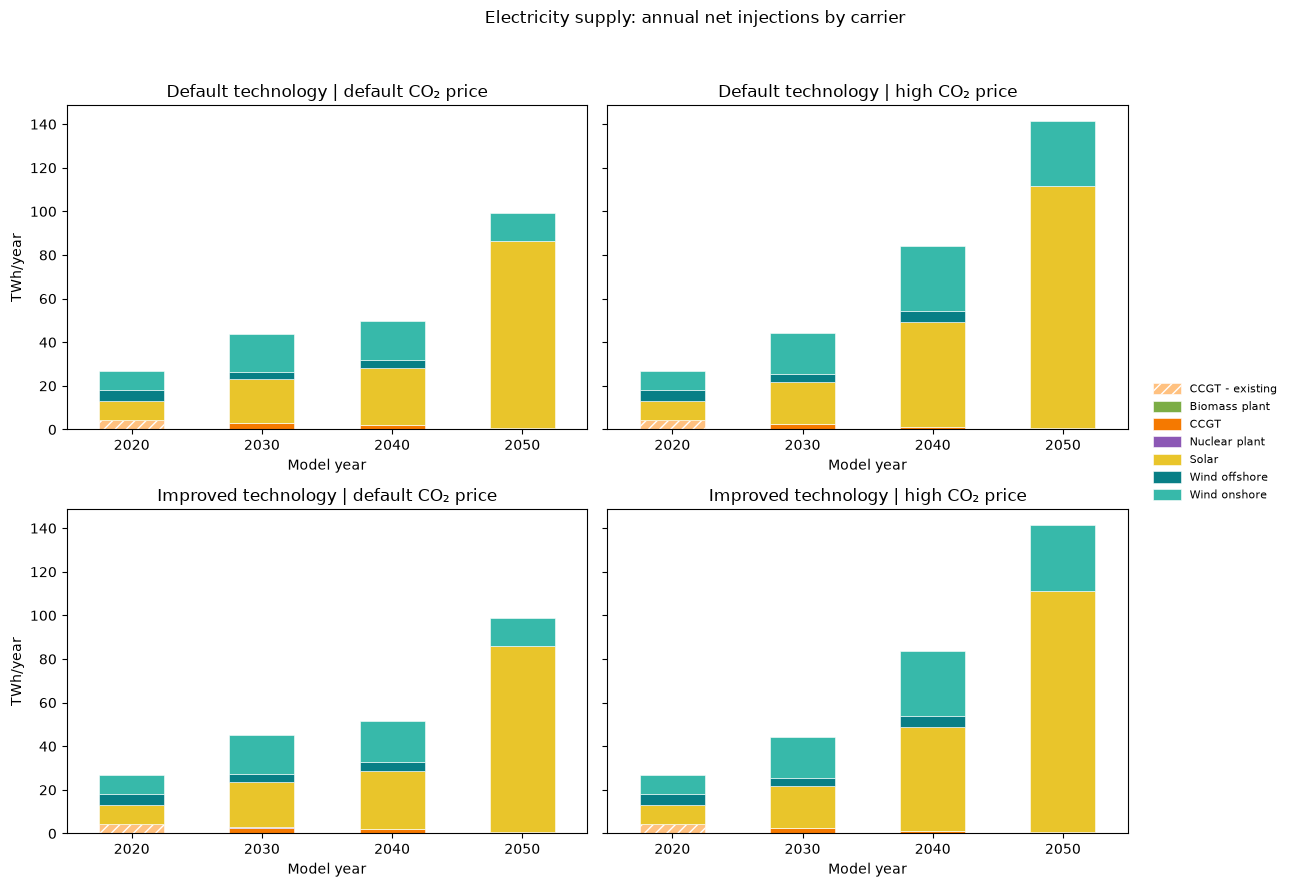

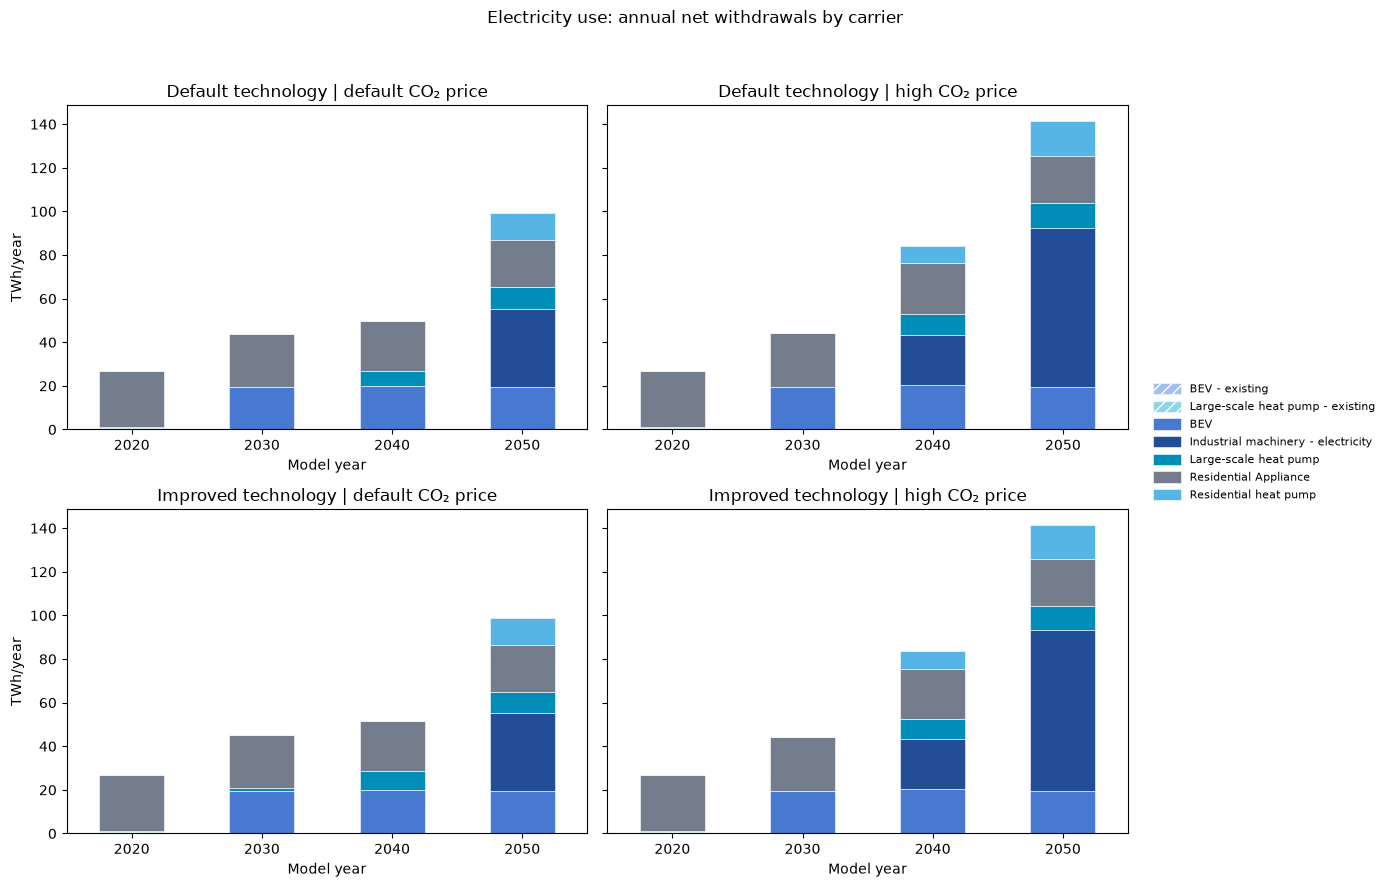

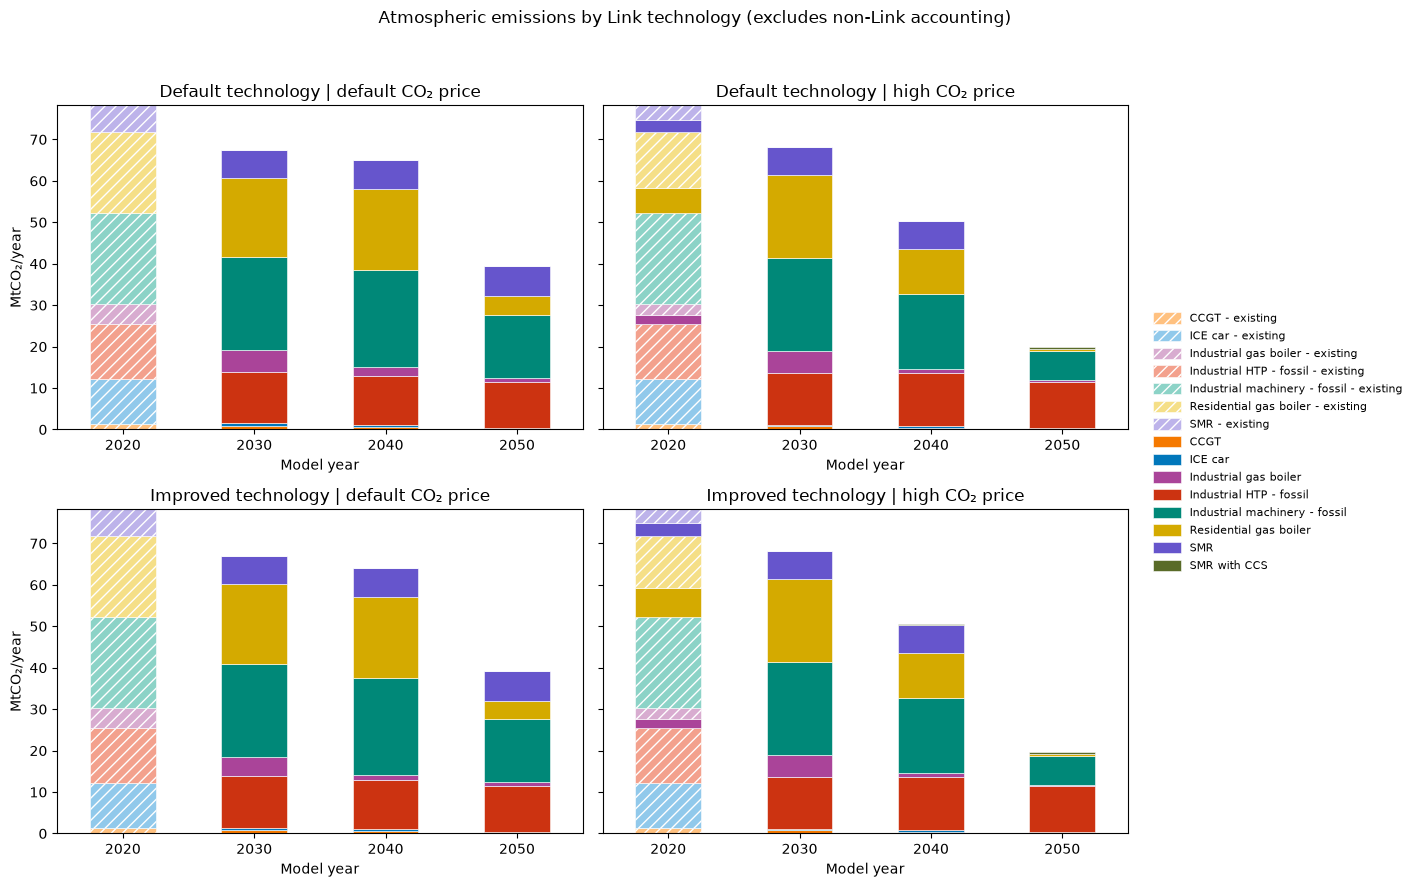

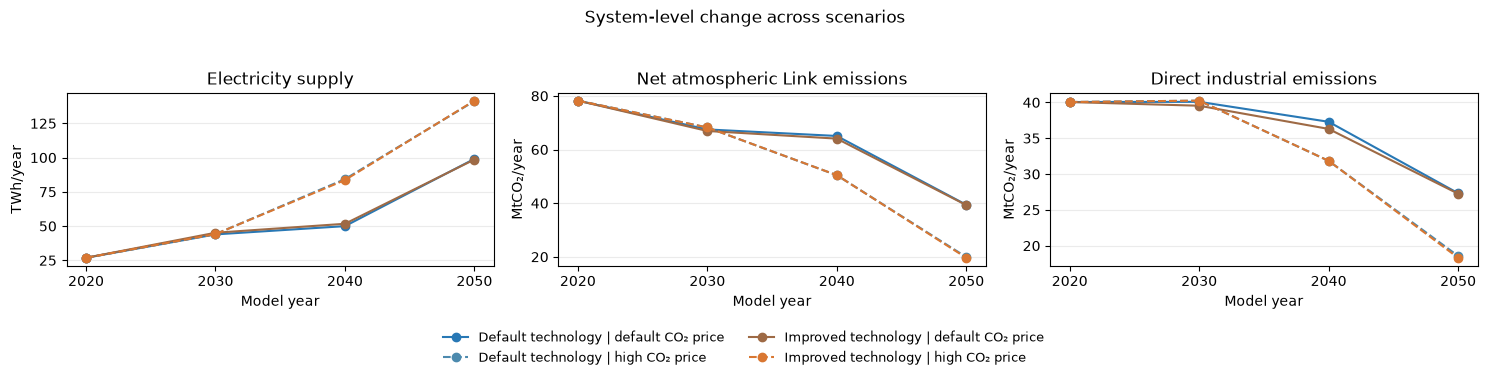


AVAILABLE BUS CARRIERS: ['Biomass', 'CO2 atmosphere', 'CO2 storage', 'Electricity', 'Gas', 'Gasoline', 'Hydrogen', 'Industrial HTP', 'Industrial LTP', 'Industrial machinery', 'Nuclear', 'Residential electricity', 'Residential heat', 'Transportation']


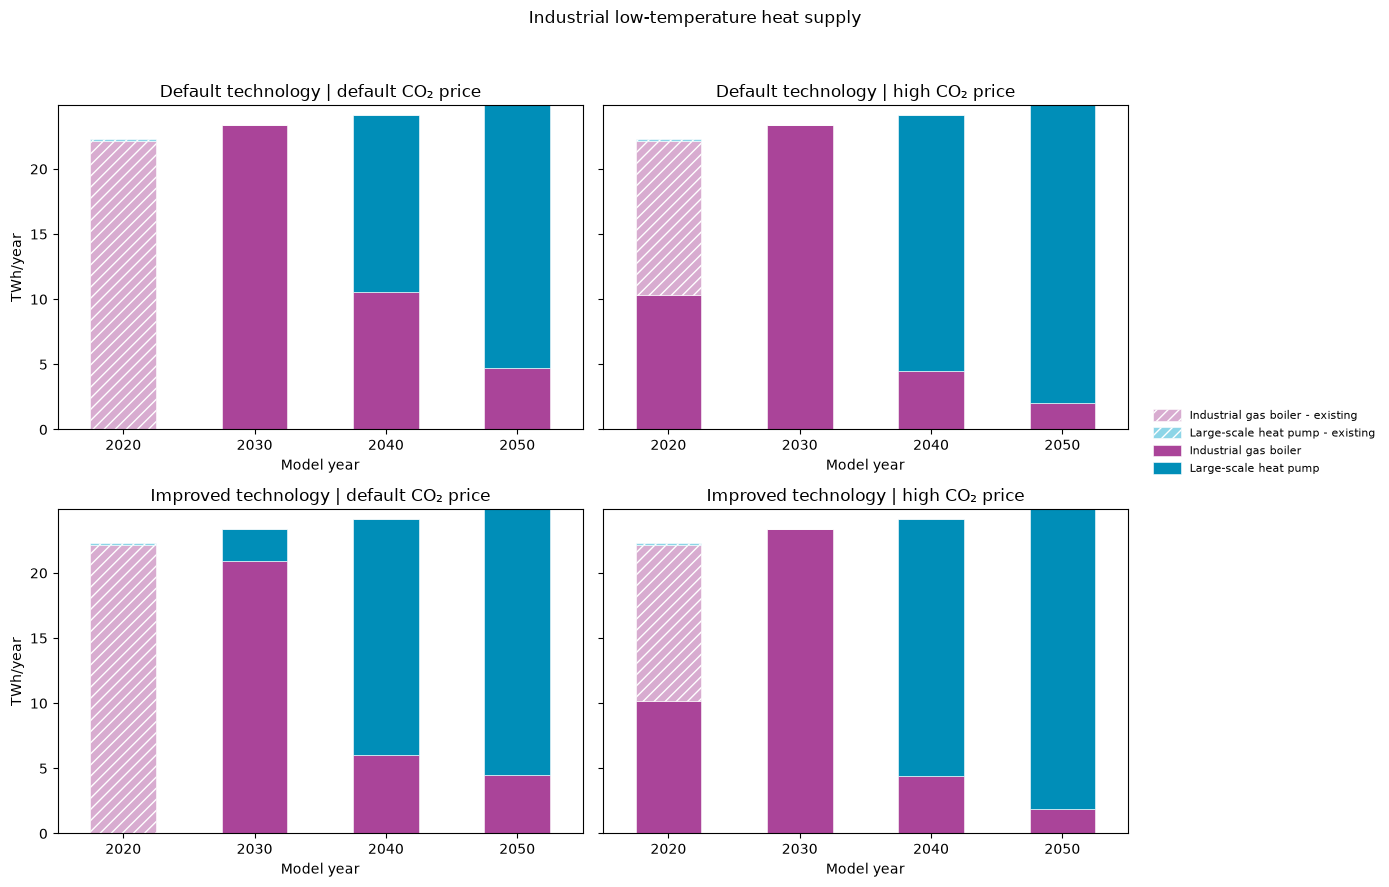

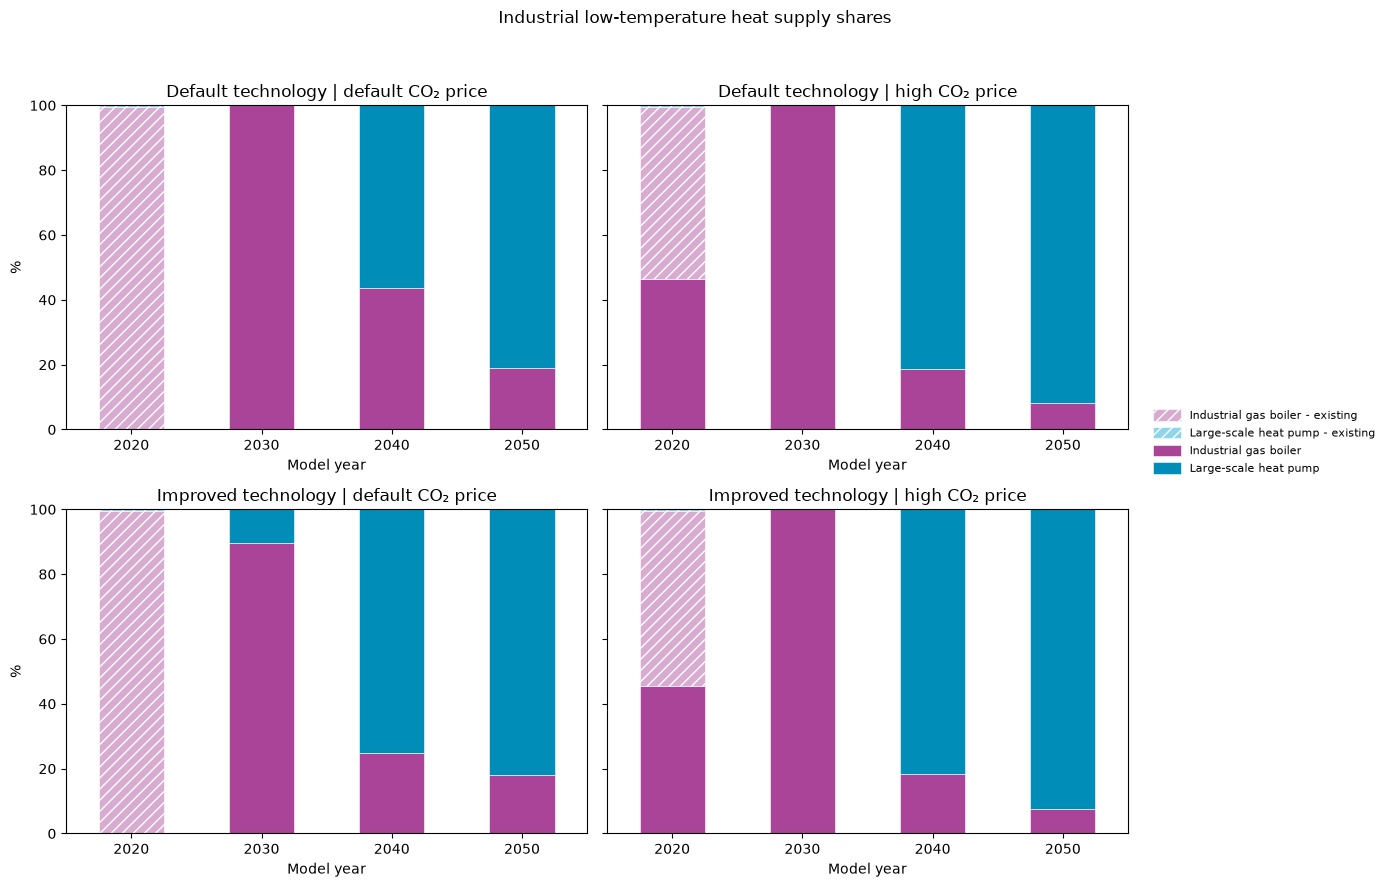

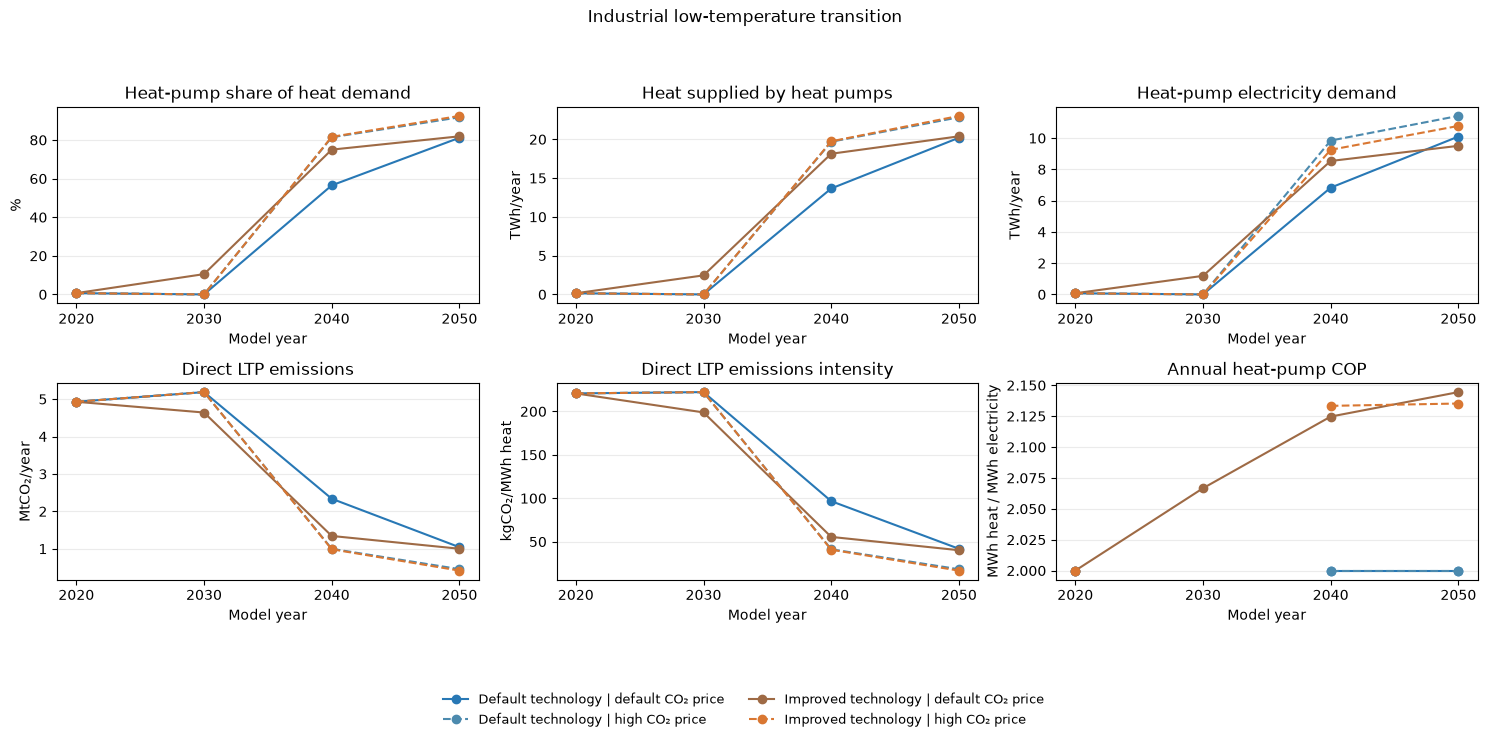


TRANSITION SPEED / ENDPOINTS
                           first_model_year_HP_share_at_least_1pct  first_model_year_HP_share_at_least_threshold  threshold_pct  last_year_HP_share_pct  last_year_direct_LTP_MtCO2  direct_LTP_reduction_first_to_last_pct
scenario                                                                                                                                                                                                                   
default_tech_low_carbon                                       2040                                          2040           50.0                  81.162                       1.042                                  78.864
default_tech_high_carbon                                      2040                                          2040           50.0                  91.775                       0.455                                  90.771
improved_tech_low_carbon                                      2030                        

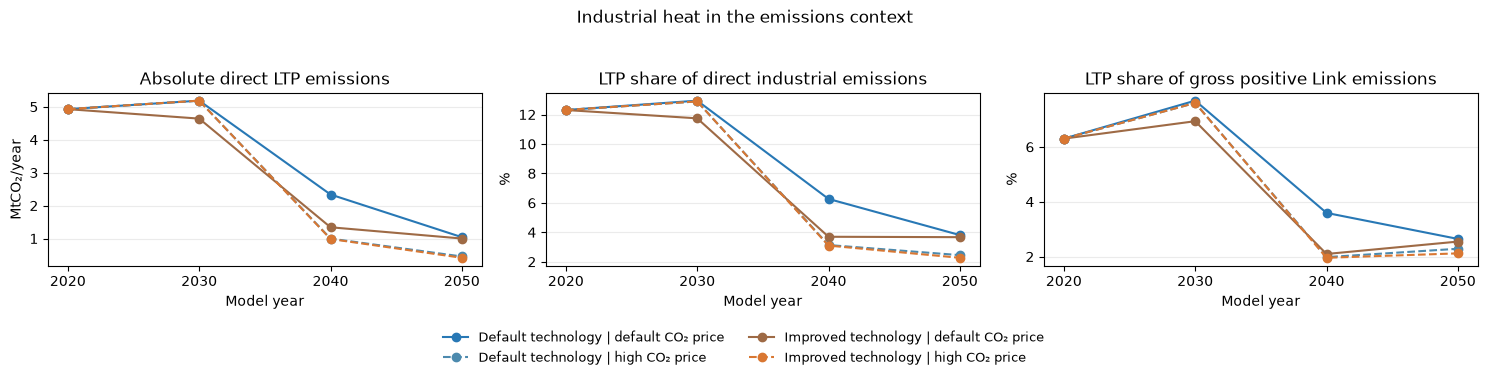

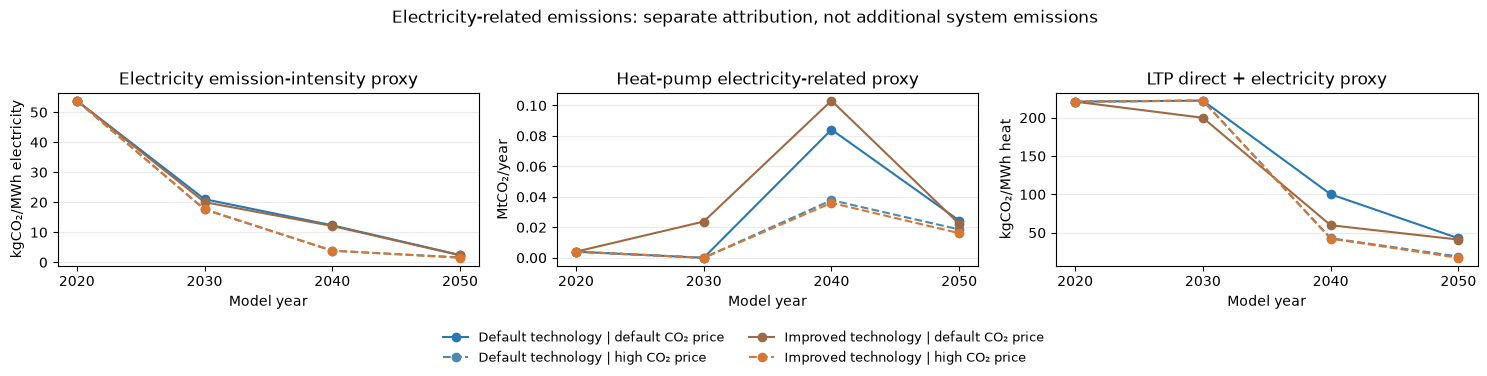


FACTORIAL SCENARIO EFFECTS: HP_share_pct
      technology_effect_at_default_carbon  technology_effect_at_high_carbon  carbon_effect_at_default_technology  carbon_effect_at_improved_technology  interaction_difference_in_differences
year                                                                                                                                                                                         
2020                               0.0000                            0.0000                               0.0000                                0.0000                                 0.0000
2030                              10.5171                            0.0000                               0.0000                              -10.5171                               -10.5171
2040                              18.5182                            0.2160                              24.9214                                6.6192                               -18.3022
2050    

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_25883/830012130.py:28: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  mask = n.get_active_assets('Link', year).reindex(links).fillna(False)
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_25883/830012130.py:28: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  mask = n.get_active_assets('Link', year).reindex(links).fillna(False)
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_25883/830012130.py:28: DeprecatedWarning: get_active_assets is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `n.components[c].get_active_assets` instead.
  mask = n.get_active_assets('Link', year).reindex(links).fillna(False)
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_25883/830012130.py:28: DeprecatedWarning: get_active_


ATTRIBUTED HEAT-SUPPLY COSTS — NOT incremental whole-system switching costs
                                heat_TWh  direct_Link_operating_cost_MEUR  input_shadow_value_MEUR  annual_capital_charge_MEUR  attributed_operating_EUR_per_MWh  attributed_total_EUR_per_MWh  input_Gas_MEUR  input_Electricity_MEUR
scenario                  year                                                                                                                                                                                                        
default_tech_high_carbon  2020    22.329                         1180.237                    7.438                         NaN                            53.190                           NaN             0.0                   7.438
                          2030    23.342                         1242.066                    0.000                         NaN                            53.211                           NaN             0.0                   0.000

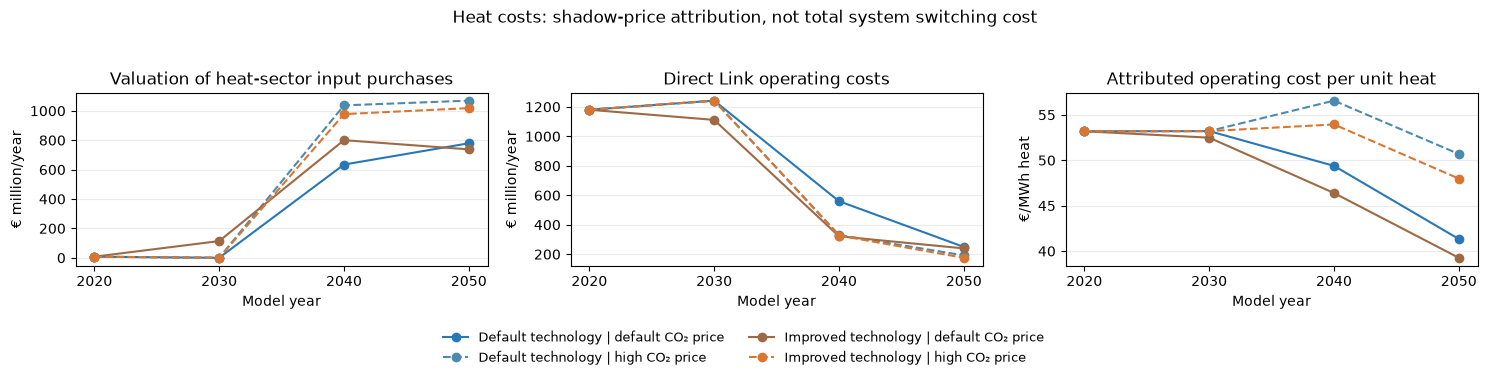


SAVED SYSTEM OBJECTIVES — compare only under identical objective accounting
                           saved_objective_model_units  objective_constant_model_units
scenario                                                                              
default_tech_low_carbon                   2.090425e+12                             0.0
default_tech_high_carbon                  2.224079e+12                             0.0
improved_tech_low_carbon                  2.089449e+12                             0.0
improved_tech_high_carbon                 2.222874e+12                             0.0

INVESTMENT-PERIOD WEIGHTS: Default technology | default CO₂ price
        objective  years
period                  
2020     9.566018     10
2030     8.659991     10
2040     7.839777     10
2050     7.097248     10

INVESTMENT-PERIOD WEIGHTS: Default technology | high CO₂ price
        objective  years
period                  
2020     9.566018     10
2030     8.659991     10
2040     7.839777   

In [6]:
# Existing networks, SCENARIOS, LABELS and COLORS are reused.
palette = globals().get('tech_colors', {})

# Optional configuration. Leave None until the relevant classification/convention
# has been verified; the code still produces the physical transition figures.
INDUSTRIAL_EMISSION_CARRIERS = None
# None uses a provisional 'Industrial...' name rule plus all LTP suppliers.
# Set an explicit list if industrial hydrogen production, CHP, etc. should be included.

ANNUAL_CAPITAL_FACTOR = None
# Set 1.0 ONLY if capital_cost is already annualised €/MW-input/year.
# Otherwise supply a callable(n, link, year) matching your model's cost convention.

FUEL_BUS_CARRIERS = []
# After checking the printed bus carriers, insert exact names for gas, biomass,
# hydrogen, etc., e.g. whichever gas carrier actually exists in your model.
# These are carrier balances, NOT automatically primary-energy inventories.

# A. Build a common set of indicators for all years and scenarios.
system_metrics, ltp_heat_mix, system_emission_mix, classifications = sys_transition_tables(
    networks, SCENARIOS, industrial_carriers=INDUSTRIAL_EMISSION_CARRIERS
)
print('\nCLASSIFICATION USED — audit before interpreting sector emission shares')
for scenario, items in classifications.items():
    print(f'\n{LABELS[scenario]}')
    for heading, carriers in items.items():
        print(heading + ':', carriers)

print('\nALL SYSTEM / TRANSITION INDICATORS')
print(system_metrics.round(4).to_string())

# B. System-wide electricity supply and consumption, all model years.
electricity_balances = sys_plot_electricity(networks, SCENARIOS, LABELS, palette)

sys_plot_stacks(system_emission_mix, SCENARIOS, LABELS,
                'Atmospheric emissions by Link technology (excludes non-Link accounting)',
                'MtCO₂/year', palette)

sys_plot_lines(system_metrics, [
    ('electricity_supply_net_by_carrier_TWh', 'Electricity supply', 'TWh/year'),
    ('system_net_Link_MtCO2', 'Net atmospheric Link emissions', 'MtCO₂/year'),
    ('industrial_direct_MtCO2', 'Direct industrial emissions', 'MtCO₂/year'),
], SCENARIOS, LABELS, COLORS, 'System-level change across scenarios')

# Optional fuel-system balances using exact user-confirmed carrier names.
all_bus_carriers = sorted(set().union(*(set(n.buses.carrier.dropna()) for n in networks.values())))
print('\nAVAILABLE BUS CARRIERS:', all_bus_carriers)
for carrier in FUEL_BUS_CARRIERS:
    fuel_tables = {s: sys_balance(networks[s], carrier) for s in SCENARIOS}
    sys_plot_stacks(fuel_tables, SCENARIOS, LABELS,
                    f'{carrier}: supply (+) and use (−)', 'TWh/year', palette)

# C. LTP heat transition: absolute output and supply shares.
sys_plot_stacks(ltp_heat_mix, SCENARIOS, LABELS,
                'Industrial low-temperature heat supply', 'TWh/year', palette)
sys_plot_stacks(ltp_heat_mix, SCENARIOS, LABELS,
                'Industrial low-temperature heat supply shares', '%', palette, normalise=True)

sys_plot_lines(system_metrics, [
    ('HP_share_pct', 'Heat-pump share of heat demand', '%'),
    ('HP_heat_TWh', 'Heat supplied by heat pumps', 'TWh/year'),
    ('HP_electricity_TWh', 'Heat-pump electricity demand', 'TWh/year'),
    ('LTP_direct_MtCO2', 'Direct LTP emissions', 'MtCO₂/year'),
    ('LTP_direct_intensity_kgCO2_per_MWh', 'Direct LTP emissions intensity', 'kgCO₂/MWh heat'),
    ('annual_HP_COP', 'Annual heat-pump COP', 'MWh heat / MWh electricity'),
], SCENARIOS, LABELS, COLORS, 'Industrial low-temperature transition')

speed_summary, speed_intervals = sys_transition_speed(system_metrics, SCENARIOS)
print('\nTRANSITION SPEED / ENDPOINTS')
print(speed_summary.round(3).to_string())
print('\nCHANGE BETWEEN MODELED YEARS — descriptive interval averages, not annual trajectories')
print(speed_intervals.round(3).to_string(index=False))

# D. LTP emissions in the wider industrial and system context.
sys_plot_lines(system_metrics, [
    ('LTP_direct_MtCO2', 'Absolute direct LTP emissions', 'MtCO₂/year'),
    ('LTP_share_industrial_emissions_pct', 'LTP share of direct industrial emissions', '%'),
    ('LTP_share_gross_system_emissions_pct', 'LTP share of gross positive Link emissions', '%'),
], SCENARIOS, LABELS, COLORS, 'Industrial heat in the emissions context')

# Separate plot: do not add these attributed electricity emissions to the system
# inventory, because electricity-generation emissions are already counted there.
sys_plot_lines(system_metrics, [
    ('electricity_average_Link_CO2_kg_per_MWh_PROXY', 'Electricity emission-intensity proxy', 'kgCO₂/MWh electricity'),
    ('HP_electricity_related_MtCO2_PROXY', 'Heat-pump electricity-related proxy', 'MtCO₂/year'),
    ('LTP_direct_plus_electricity_kgCO2_per_MWh_PROXY', 'LTP direct + electricity proxy', 'kgCO₂/MWh heat'),
], SCENARIOS, LABELS, COLORS, 'Electricity-related emissions: separate attribution, not additional system emissions')

# E. Technology versus carbon-price effects; useful for interpreting all four cases.
for indicator in ['HP_share_pct', 'LTP_direct_MtCO2', 'HP_electricity_TWh', 'system_net_Link_MtCO2']:
    print(f'\nFACTORIAL SCENARIO EFFECTS: {indicator}')
    print(sys_factorial_effects(system_metrics, indicator).round(4).to_string())

# F. Cost attribution; total attributed annual heat cost is left NaN until
# investment annualisation has been confirmed.
heat_costs = sys_attributed_heat_costs(
    networks, SCENARIOS, annual_capital_factor=ANNUAL_CAPITAL_FACTOR
)
if not heat_costs.empty:
    print('\nATTRIBUTED HEAT-SUPPLY COSTS — NOT incremental whole-system switching costs')
    print(heat_costs.round(3).to_string())
    if set(SCENARIOS).issubset(heat_costs.index.get_level_values('scenario')):
        fields = [
            ('input_shadow_value_MEUR', 'Valuation of heat-sector input purchases', '€ million/year'),
            ('direct_Link_operating_cost_MEUR', 'Direct Link operating costs', '€ million/year'),
            ('attributed_operating_EUR_per_MWh', 'Attributed operating cost per unit heat', '€/MWh heat'),
        ]
        if ANNUAL_CAPITAL_FACTOR is not None:
            fields += [
                ('annual_capital_charge_MEUR', 'Annual heat-sector investment charge', '€ million/year'),
                ('attributed_total_EUR_per_MWh', 'Attributed total heat-supply cost', '€/MWh heat'),
            ]
        sys_plot_lines(heat_costs, fields, SCENARIOS, LABELS, COLORS,
                       'Heat costs: shadow-price attribution, not total system switching cost')

objective_comparison = sys_objective_table(networks, SCENARIOS)
print('\nSAVED SYSTEM OBJECTIVES — compare only under identical objective accounting')
print(objective_comparison.to_string())
for scenario in SCENARIOS:
    print(f'\nINVESTMENT-PERIOD WEIGHTS: {LABELS[scenario]}')
    print(networks[scenario].investment_period_weightings.to_string())

# G. Inspect non-Link atmospheric components; some are bookkeeping, others may
# be physical emissions/removals. Their interpretation is not inferred here.
for scenario in SCENARIOS:
    n = networks[scenario]
    atmospheric_buses = n.buses.index[n.buses.carrier.eq('CO2 atmosphere')]
    print(f'\nNON-LINK ATMOSPHERIC COMPONENTS: {LABELS[scenario]}')
    for component in ['stores', 'loads', 'generators', 'storage_units']:
        assets = getattr(n, component)
        if not assets.empty:
            attached = assets[assets.bus.isin(atmospheric_buses)]
            if not attached.empty:
                print(component)
                print(attached[[c for c in ['bus', 'carrier'] if c in attached]].to_string())

In [87]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(10, 4)

    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1)).T
    df.plot(kind='bar', stacked='True', rot=0, colormap="tab20", ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title(scen.name)

    fig.tight_layout()

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


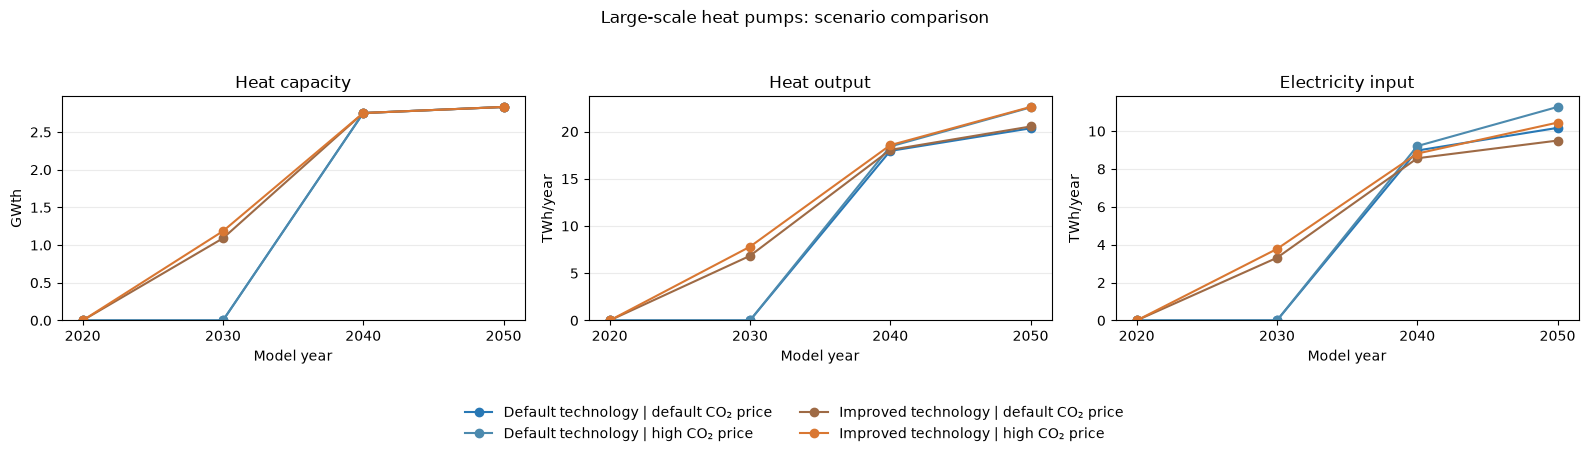

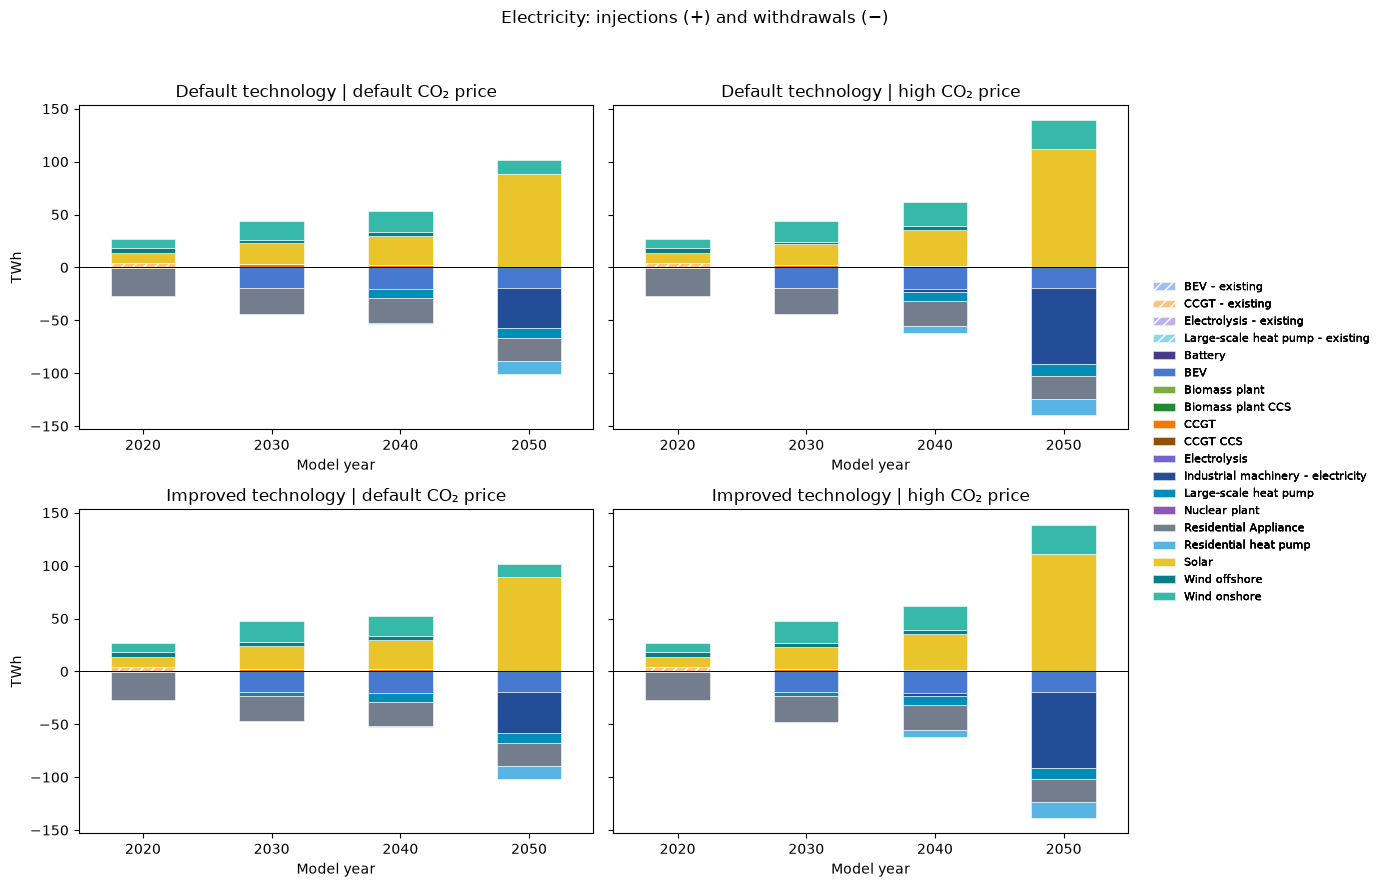

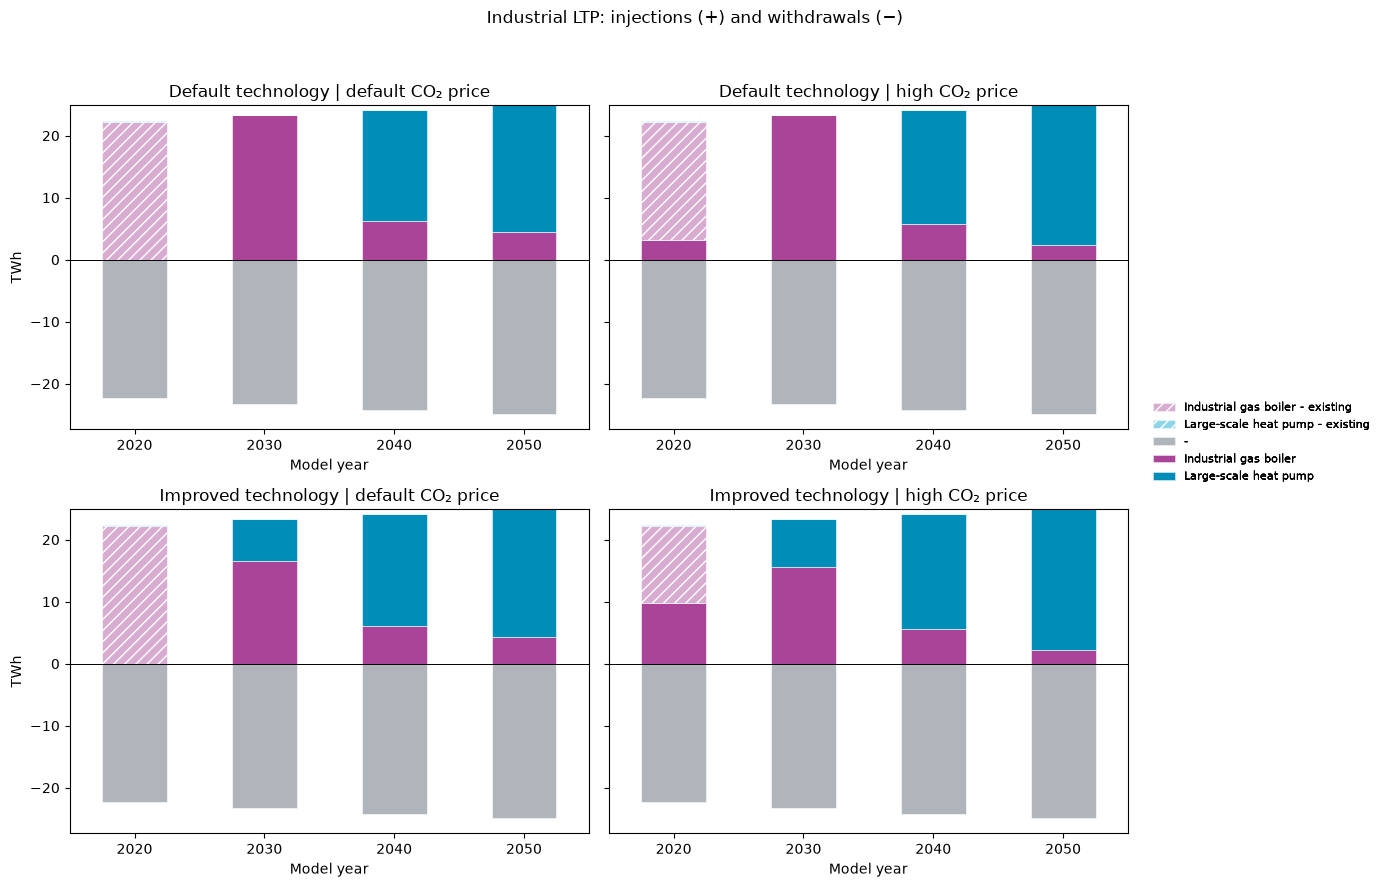

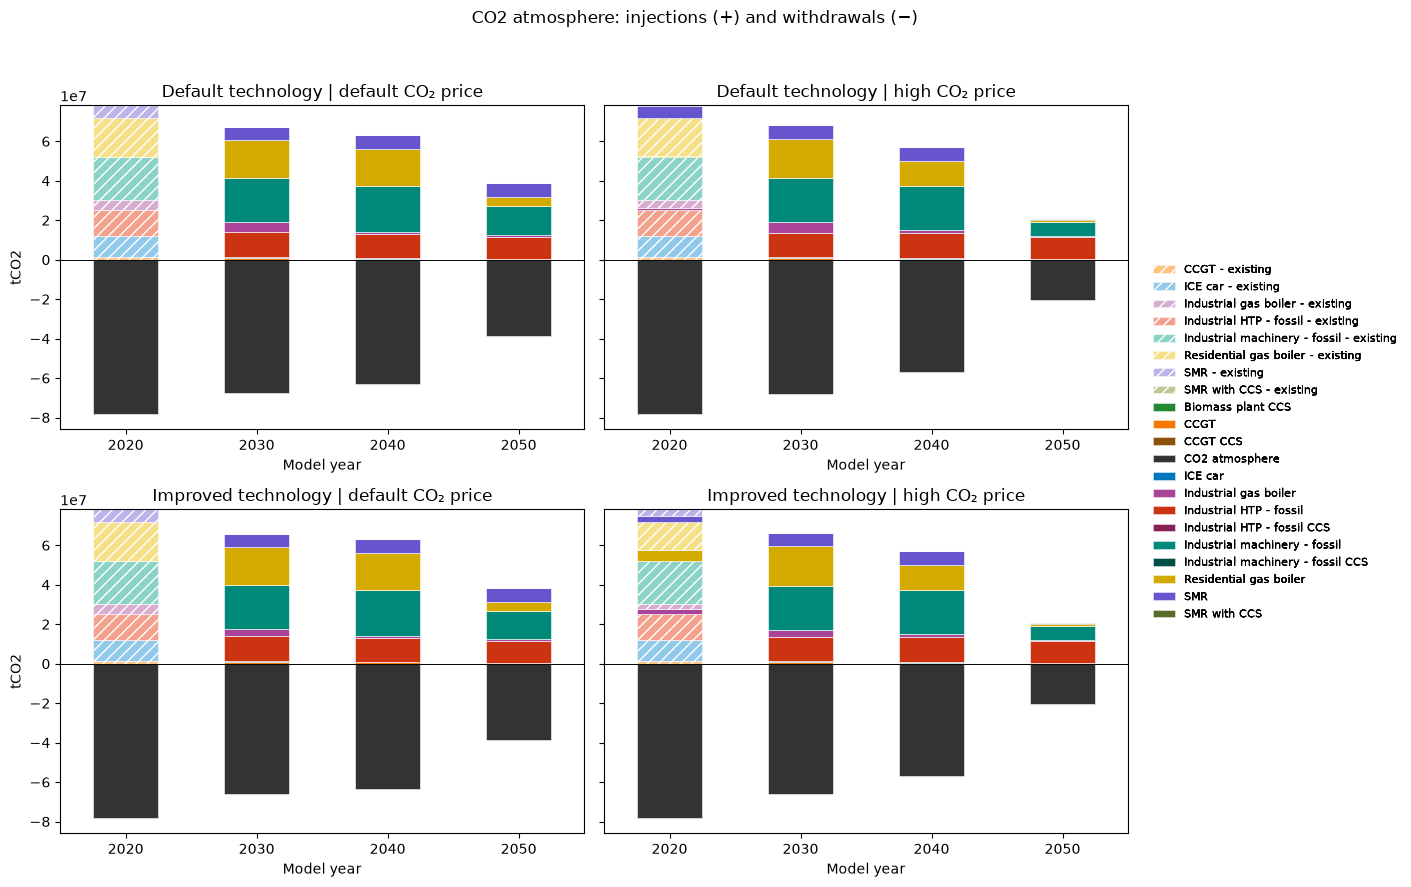

In [88]:
def heatpump_metrics(n):
    """Active output capacity, annual heat, and annual electricity input.

    Assumes the heat pump is a Link with electricity at bus0 and useful
    heat at bus1, as in the model's two-bus Link implementation.
    Includes active older investment vintages, not just new builds.
    """
    if not isinstance(n.snapshots, pd.MultiIndex):
        raise ValueError("Expected multi-period snapshots (period, timestamp).")

    hp = n.links.index[n.links["carrier"].eq("Large-scale heat pump")]
    if len(hp) == 0:
        raise ValueError(f"No large-scale heat-pump Links found in {n.name}.")

    missing = hp.difference(n.links_t.p0.columns).union(
        hp.difference(n.links_t.p1.columns)
    )
    if len(missing):
        raise ValueError(f"Missing optimized heat-pump dispatch: {list(missing)}")

    periods = list(n.investment_periods)
    result = pd.DataFrame(
        index=pd.Index(periods, name="Model year"),
        columns=["Heat capacity (GWth)", "Heat output (TWh/year)",
                 "Electricity input (TWh/year)"],
        dtype=float,
    )

    for year in periods:
        # Link p_nom is input capacity. Multiply by COP/efficiency to obtain
        # heat-output capacity. Do not sum expired or future vintages.
        active_mask = (
            n.links.loc[hp, "build_year"].le(year)
            & (n.links.loc[hp, "build_year"] + n.links.loc[hp, "lifetime"]).gt(year)
        )
        active = hp[active_mask.to_numpy()]
        result.loc[year, "Heat capacity (GWth)"] = (
            n.links.loc[active, "p_nom_opt"]
            * n.links.loc[active, "efficiency"]
        ).sum() / 1e3

        snapshots = n.snapshots[n.snapshots.get_level_values(0) == year]
        # These weights account for the hours represented by each snapshot.
        # Do not multiply by the decade's investment-period weighting here:
        # the result is annual energy, not total energy over the whole decade.
        weights = n.snapshot_weightings.loc[snapshots, "generators"]
        heat = -n.links_t.p1.loc[snapshots, hp].sum(axis=1)
        electricity = n.links_t.p0.loc[snapshots, hp].sum(axis=1)
        result.loc[year, "Heat output (TWh/year)"] = heat.mul(weights).sum() / 1e6
        result.loc[year, "Electricity input (TWh/year)"] = (
            electricity.mul(weights).sum() / 1e6
        )

    return result


metrics = {scenario: heatpump_metrics(n) for scenario, n in networks.items()}

# FIGURE 1: Direct comparison of the heat-pump results.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, next(iter(metrics.values())).columns):
    for scenario in SCENARIOS:
        ax.plot(
            metrics[scenario].index,
            metrics[scenario][metric],
            label=LABELS[scenario],
            color=COLORS[scenario],
            linestyle="--" if scenario.endswith("high") else "-",
            marker="o",
        )
    ax.set_title(metric.split(" (")[0])
    ax.set_ylabel(metric.split("(")[1].rstrip(")"))
    ax.set_xlabel("Model year")
    ax.set_xticks(next(iter(metrics.values())).index)
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Large-scale heat pumps: scenario comparison")
fig.tight_layout(rect=[0, 0.16, 1, 0.94])
plt.show()


def plot_energy_balance_comparison(bus_carrier="Electricity", unit="TWh"):
    """Four stacked energy balances, adapted from the supplied functions.

    Positive bars are injections into the selected bus carrier;
    negative bars are withdrawals. Values use PyPSA's statistics aggregation.
    Suitable for energy carriers; use unit='tCO2' for emissions carriers.
    """
    if unit not in {"TWh", "MWh", "tCO2"}:
        raise ValueError("Choose TWh, MWh, or tCO2.")
    scale = 1e6 if unit == "TWh" else 1.0
    balances = {}
    for scenario, n in networks.items():
        df = n.statistics.energy_balance(bus_carrier=bus_carrier)
        if not isinstance(df, pd.DataFrame):
            raise ValueError("Expected statistics columns to represent model years.")
        if not set(n.investment_periods).issubset(df.columns):
            raise ValueError(f"Unexpected statistics columns: {list(df.columns)}")
        if df.empty:
            raise ValueError(f"No energy balance found for {bus_carrier!r}.")
        # Aggregate duplicate carriers rather than simply relabelling rows.
        if isinstance(df.index, pd.MultiIndex):
            level = "carrier" if "carrier" in df.index.names else 1
            df = df.groupby(level=level).sum()
        else:
            df = df.groupby(level=0).sum()
        balances[scenario] = df.loc[:, list(n.investment_periods)].T / scale

    carriers = sorted(set().union(*(set(df.columns) for df in balances.values())))
    # Retrieve carrier colors from your tech_colors dictionary.
    # Use neutral grey for carriers without a defined color.
    colors = {c: tech_colors.get(c, "#B0B5BC") for c in carriers}
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    for ax, scenario in zip(axes.flat, SCENARIOS):
        df = balances[scenario].reindex(columns=carriers, fill_value=0).fillna(0)
        df.plot.bar(
            stacked=True,
            rot=0,
            ax=ax,
            color=[colors[c] for c in carriers],
            edgecolor="white",
            linewidth=0.4,
            legend=False,
        )
        # Each container corresponds to one carrier in the stacked bar chart.
        for carrier, container in zip(carriers, ax.containers):
            if carrier.endswith(" - existing"):
                for bar in container:
                    bar.set_hatch("///")
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(LABELS[scenario])
        ax.set_ylabel(unit)
        ax.set_xlabel("Model year")
        ax.grid(False)
        handles, labels = axes.flat[0].get_legend_handles_labels()

        # Existing technologies first; alphabetical order within each group.
        legend_items = sorted(
            zip(handles, labels),
            key=lambda item: (
                not item[1].endswith(" - existing"),
                item[1].lower(),),)

        sorted_handles, sorted_labels = zip(*legend_items)

        fig.legend( sorted_handles, sorted_labels, loc="center left", bbox_to_anchor=(0.82, 0.5), 
                   frameon=False,
                    fontsize=8,)
        
    fig.suptitle(f"{bus_carrier}: injections (+) and withdrawals (−)")
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()


# FIGURE 2: Electricity balances for all four scenarios.
plot_energy_balance_comparison("Electricity", unit="TWh")

# Optional: uncomment ONE of these to inspect another balance.
# Use exact bus-carrier names from your input database.
# plot_energy_balance_comparison("Residential heat", unit="TWh")
plot_energy_balance_comparison("Industrial LTP", unit="TWh")
# plot_energy_balance_comparison("Hydrogen", unit="TWh")
plot_energy_balance_comparison("CO2 atmosphere", unit="tCO2")